# Jawad Hassan 2230-0035
# BS AI
# CV LAB # Mid
# Sir Zeeshan Aslam



# Task 1 Problem understanding and Img Analysis:
### Real World Problem: Pneumocephalus (skull x-ray): https://radiopaedia.org/cases/pneumocephalus-skull-x-ray?lang=us
### Case Discussion:A polytrauma patient presented with change in behavior and incontinence.
### This young male polytrauma patient presented with behavioral changes and urinary incontinence. Skull x-ray frontal sinus fractures with large encysted bilateral frontal lobe pneumocephalus having extension to the lateral ventricle and cisterns. Emergency cranialization procedure with bifrontal craniotomy done for air extraction and dura sealed.


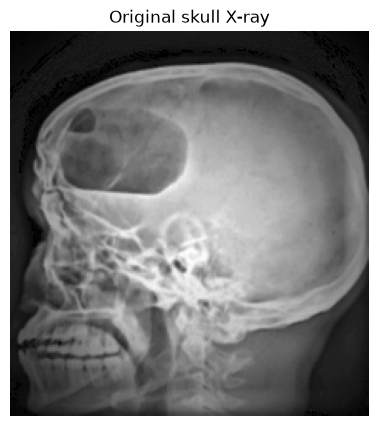

Shape: (250, 233) dtype: uint8 range: (np.uint8(0), np.uint8(214))


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the image in grayscale (X-rays are naturally grayscale)
image = cv2.imread('pneumocephalus-skull-x-ray.png', cv2.IMREAD_GRAYSCALE)

# Sanity check - make sure it actually loaded
if image is None:
    raise FileNotFoundError("Image not found - check the filename/path")

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray")
plt.title("Original skull X-ray")
plt.axis("off")
plt.show()

print("Shape:", image.shape, "dtype:", image.dtype, "range:", (image.min(), image.max()))

### This is a lateral (side-view) skull X-ray. problem visible in this image is an abnormal pocket of air inside the skull, caused by a fracture, that’s large enough and in the right spot to be pressing on the brain and causing neurological symptoms.

## Image Characteristics

### A. Fixable with preprocessing

#### 1. Very low resolution
- **Observation:** The image is only ~250 px wide, so the frontal sinus fracture lines are just a few pixels thick.
- **Fix:** Upscale with interpolation bicubic

#### 2. Noise and JPEG compression artifacts
- **Observation:** Grain and blockiness in the flat gray areas; any enhancement step will amplify it.
- **Fix:** Denoise *before* enhancing, using an edge-preserving filter: non-local means, bilateral, or median.

#### 3. Uneven brightness
- **Observation:** The face, skull base, and back of the vault are exposed differently.
- **Fix:** Background/flat-field correction, morphological top-hat, or homomorphic filtering.

#### 4. Low contrast
- **Observation:** Inside the skull, the brain is mostly one dull gray, with little separation from the air pocket.
- **Fix:** Gamma correction and CLAHE.
- **Note:** CLAHE beats global histogram equalization here. Global HE would crush the dark air region and boost noise everywhere.

#### 5. Soft, blurry edges
- **Observation:** The edge of the air pocket blurs gradually into the surrounding tissue, and the fracture lines are blurry.
- **Fix:** Unsharp masking or Laplacian sharpening, applied after denoising.

### B. Handled during segmentation

#### 6. Background as dark as the air pocket
- **Observation:** The area outside the skull has nearly the same intensity as the air pocket, so a plain threshold would merge them.
- **Fix:** Build a skull mask first (threshold → largest contour → fill holes), then segment only inside it


# Task 2 Img Processing Technique:
## Pipeline

**Enhancement:**
Load Image → Upscale → Median Filter → Top-hat / Black-hat → Gamma + CLAHE → Laplacian Sharpening → Enhanced Image

**Segmentation:**
Top-hat / Black-hat Output → Crop ROI → Intensity Level Slicing → Opening → Largest Connected Component → Hole Filling → Boundary Extraction

## Why Each Technique

**Enhancement:**
- **Upscale** → enlarges thin fracture lines
- **Median Filter** → removes noise, keeps edges
- **Top-hat / Black-hat** → fixes uneven brightness
- **Gamma + CLAHE** → boosts local contrast
- **Laplacian Sharpening** → sharpens blurry edges

**Segmentation:**
- **Crop ROI** → excludes background, overlapping bones
- **Intensity Level Slicing** → separates dark air pocket
- **Opening** → removes small noisy specks
- **Largest Connected Component** → keeps only air pocket
- **Hole Filling** → fills gaps inside pocket
- **Boundary Extraction** → outlines the air pocket

# Task 3 Implementation:

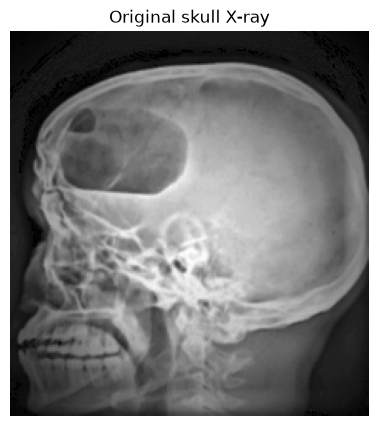

Shape: (250, 233) dtype: uint8 range: (np.uint8(0), np.uint8(214))


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the image in grayscale (X-rays are naturally grayscale)
image = cv2.imread('pneumocephalus-skull-x-ray.png', cv2.IMREAD_GRAYSCALE)

# Sanity check - make sure it actually loaded
if image is None:
    raise FileNotFoundError("Image not found - check the filename/path")

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray")
plt.title("Original skull X-ray")
plt.axis("off")
plt.show()

print("Shape:", image.shape, "dtype:", image.dtype, "range:", (image.min(), image.max()))

In [3]:
# Imports and Display Helper
from scipy import ndimage

def show_images(images, titles, figsize=None):
    if figsize is None:
        figsize = (5 * len(images), 5)
    plt.figure(figsize=figsize)
    for i, (im, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(1, len(images), i)
        plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

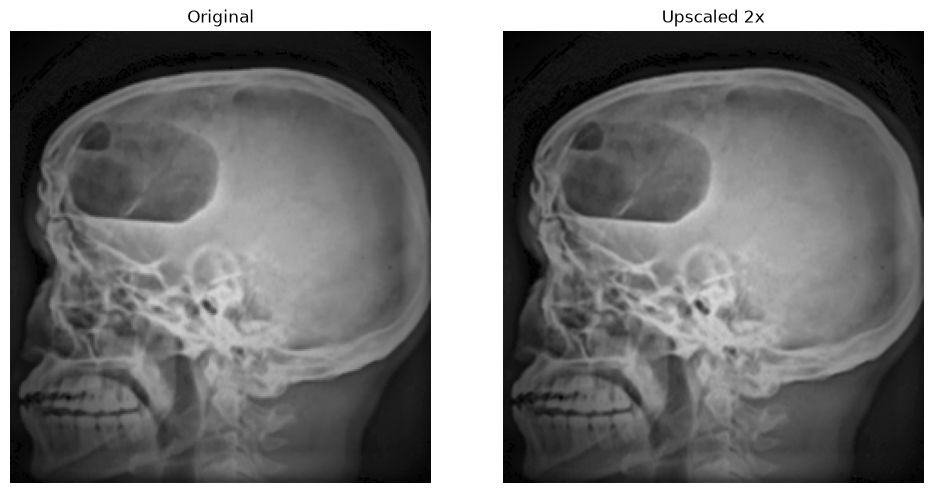

Original: (250, 233) -> Upscaled: (500, 466)


In [4]:
# Step 1 - Upscaling (Bicubic Interpolation)
upscaled = cv2.resize(image, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)

show_images([image, upscaled], ["Original", "Upscaled 2x"])
print("Original:", image.shape, "-> Upscaled:", upscaled.shape)

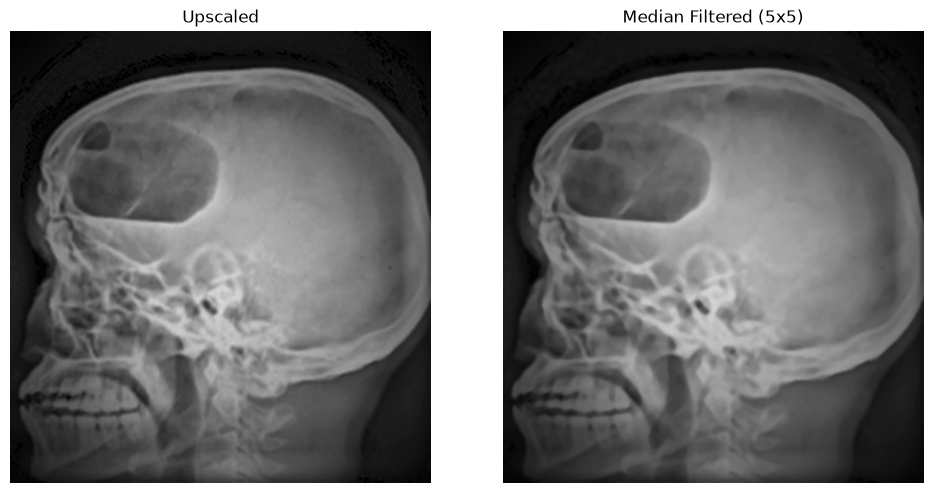

In [5]:
# Step 2 - Noise Removal (Median Filter)
denoised = cv2.medianBlur(upscaled, 5)

show_images([upscaled, denoised], ["Upscaled", "Median Filtered (5x5)"])

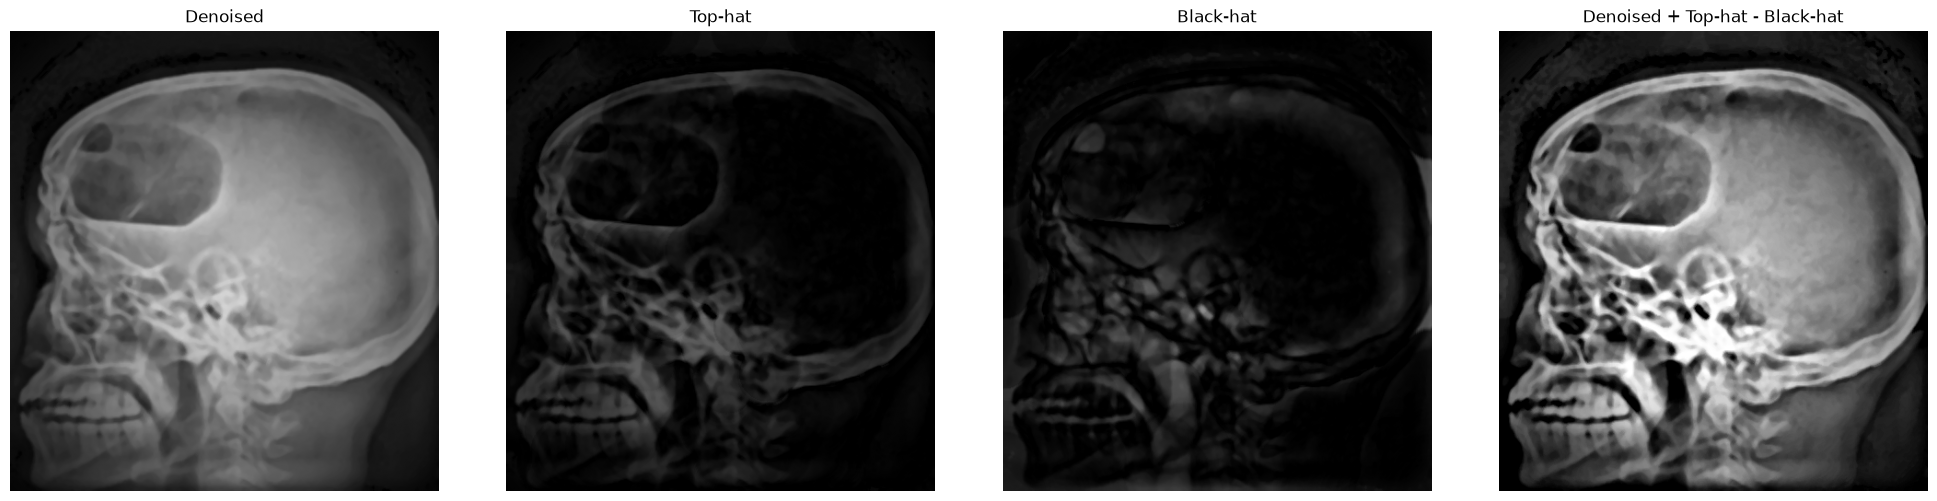

In [6]:
# Step 3 - Uneven Brightness Correction (Top-hat / Black-hat)
k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (61, 61))

tophat = cv2.morphologyEx(denoised, cv2.MORPH_TOPHAT, k)
blackhat = cv2.morphologyEx(denoised, cv2.MORPH_BLACKHAT, k)
corrected = cv2.subtract(cv2.add(denoised, tophat), blackhat)

show_images([denoised, tophat, blackhat, corrected],
            ["Denoised", "Top-hat", "Black-hat", "Denoised + Top-hat - Black-hat"])

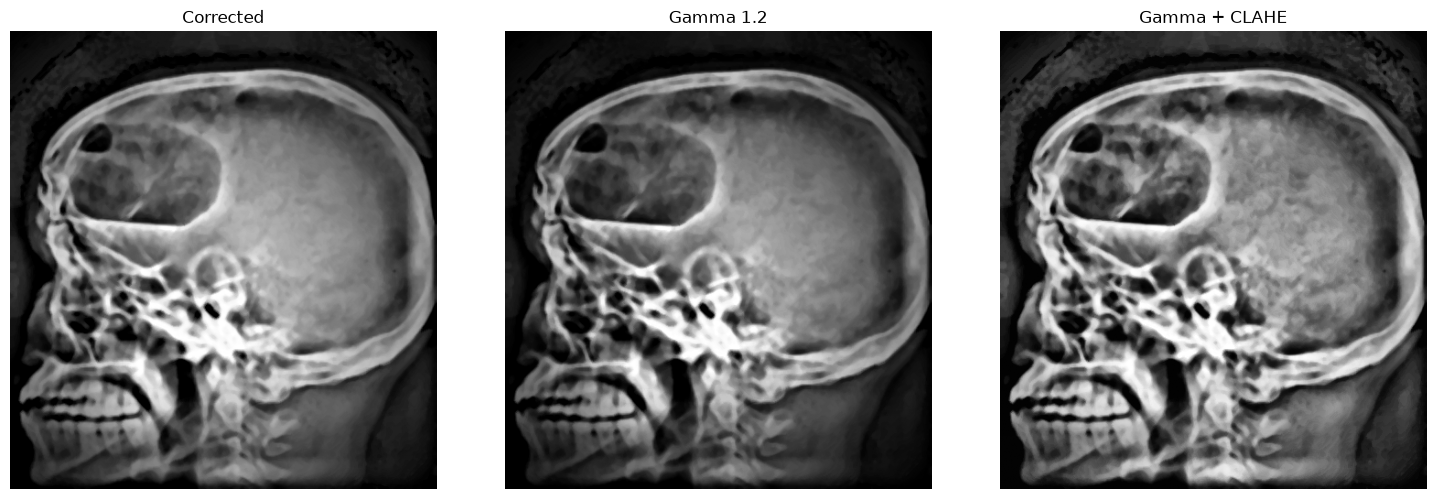

In [7]:
# Step 4 - Contrast Enhancement (Gamma Correction + CLAHE)
gamma = 1.2
gamma_img = np.array(255 * (corrected / 255) ** gamma, dtype=np.uint8)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
contrast = clahe.apply(gamma_img)

show_images([corrected, gamma_img, contrast],
            ["Corrected", f"Gamma {gamma}", "Gamma + CLAHE"])

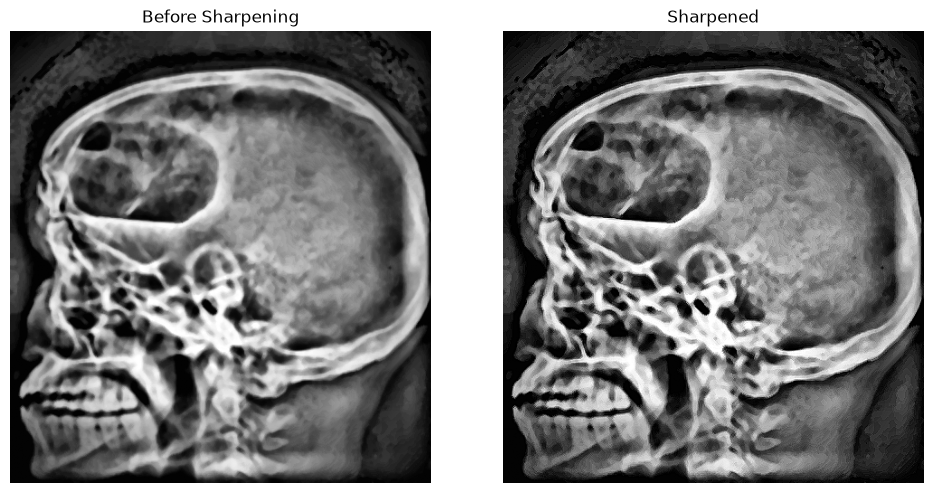

In [8]:
# Step 5 - Edge Sharpening (Laplacian)
laplacian_kernel = np.array([[0, -1, 0],
                             [-1, 4, -1],
                             [0, -1, 0]], dtype=np.float32)

laplacian = cv2.filter2D(contrast, cv2.CV_64F, laplacian_kernel)
enhanced = np.clip(contrast + 0.7 * laplacian, 0, 255).astype(np.uint8)

show_images([contrast, enhanced], ["Before Sharpening", "Sharpened"])

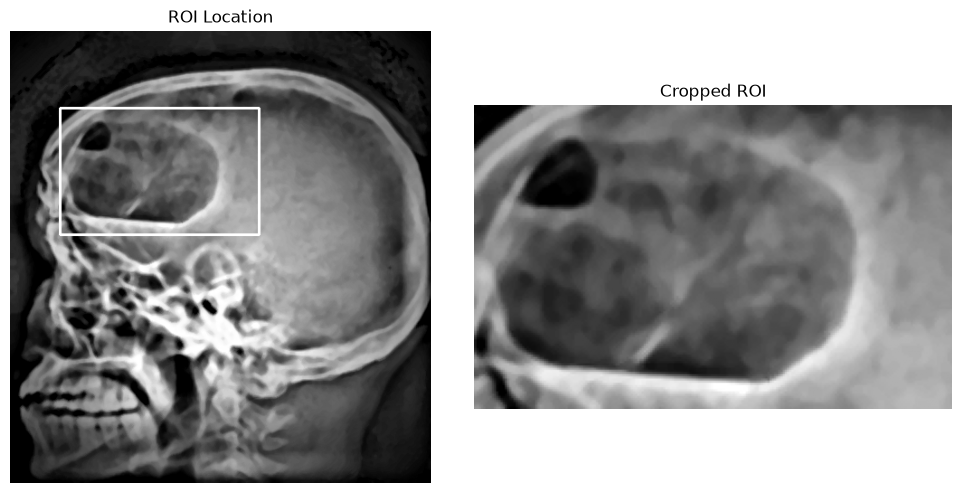

In [9]:
# Step 6 - Region of Interest (Cropping)
y1, y2, x1, x2 = 85, 225, 55, 275
roi = corrected[y1:y2, x1:x2]

boxed = corrected.copy()
cv2.rectangle(boxed, (x1, y1), (x2, y2), 255, 2)

show_images([boxed, roi], ["ROI Location", "Cropped ROI"])

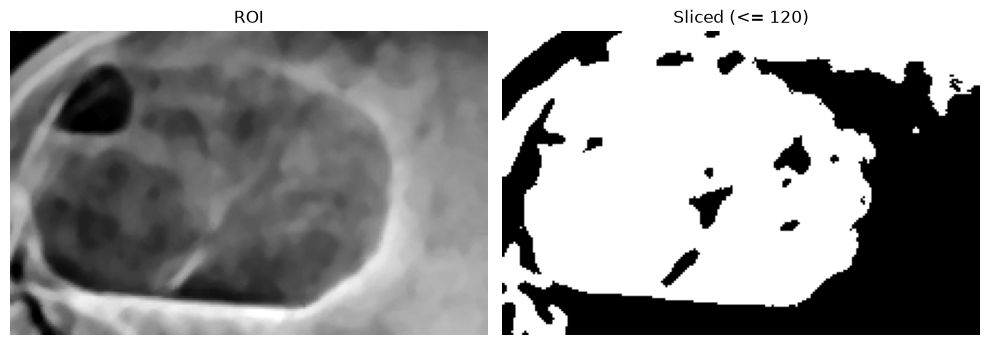

In [10]:
# Step 7 - Air Pocket Separation (Intensity Level Slicing)
T = 120
sliced = np.where(roi <= T, 255, 0).astype(np.uint8)

show_images([roi, sliced], ["ROI", f"Sliced (<= {T})"])

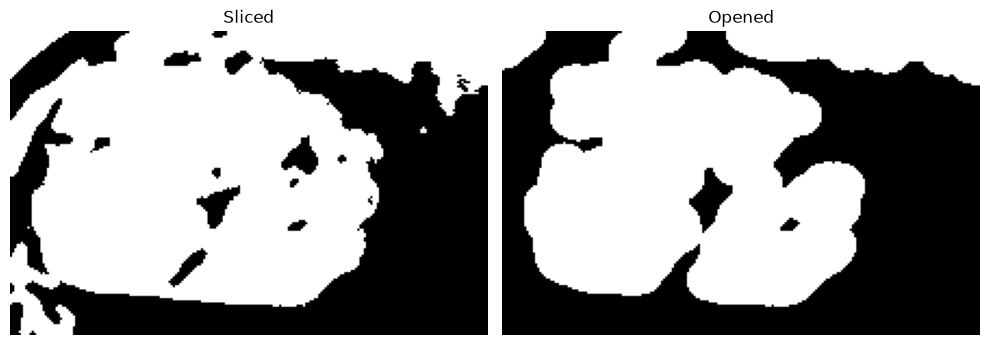

In [11]:
# Step 8 - Noise Speck Removal (Opening)
se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
opened = cv2.morphologyEx(sliced, cv2.MORPH_OPEN, se)

show_images([sliced, opened], ["Sliced", "Opened"])

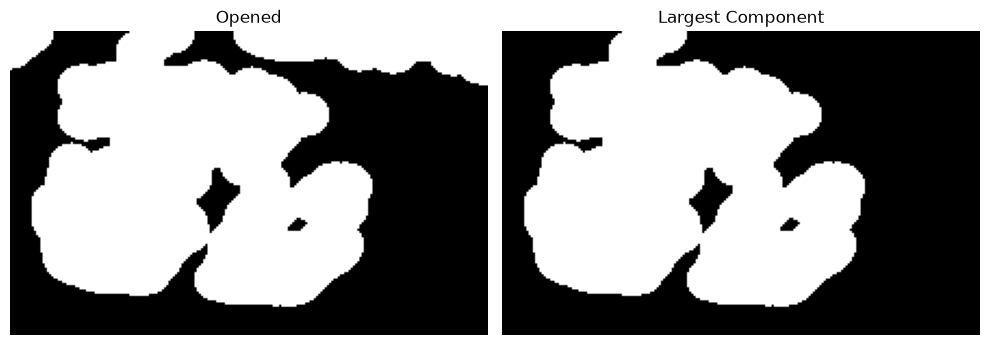

Components found: 3 | Largest area: 13817


In [12]:
# Step 9 - Largest Connected Component
n, labels, stats, centroids = cv2.connectedComponentsWithStats(opened, connectivity=8)

largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
pocket = (labels == largest).astype(np.uint8) * 255

show_images([opened, pocket], ["Opened", "Largest Component"])
print("Components found:", n - 1, "| Largest area:", stats[largest, cv2.CC_STAT_AREA])

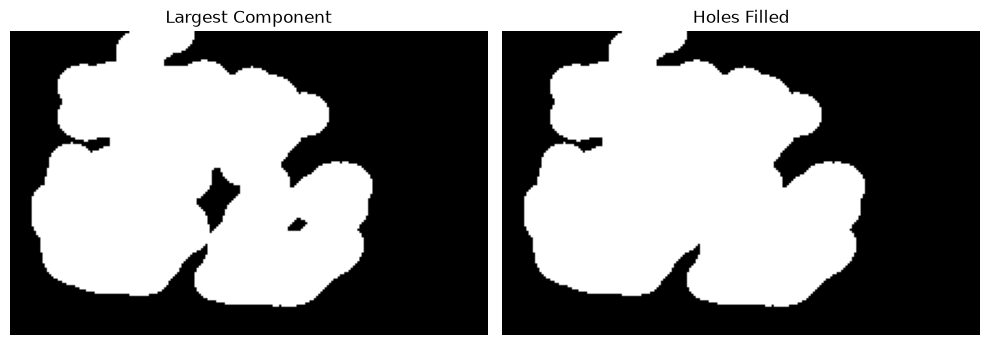

In [13]:
# Step 10 - Hole Filling
filled = ndimage.binary_fill_holes(pocket > 0).astype(np.uint8) * 255

show_images([pocket, filled], ["Largest Component", "Holes Filled"])

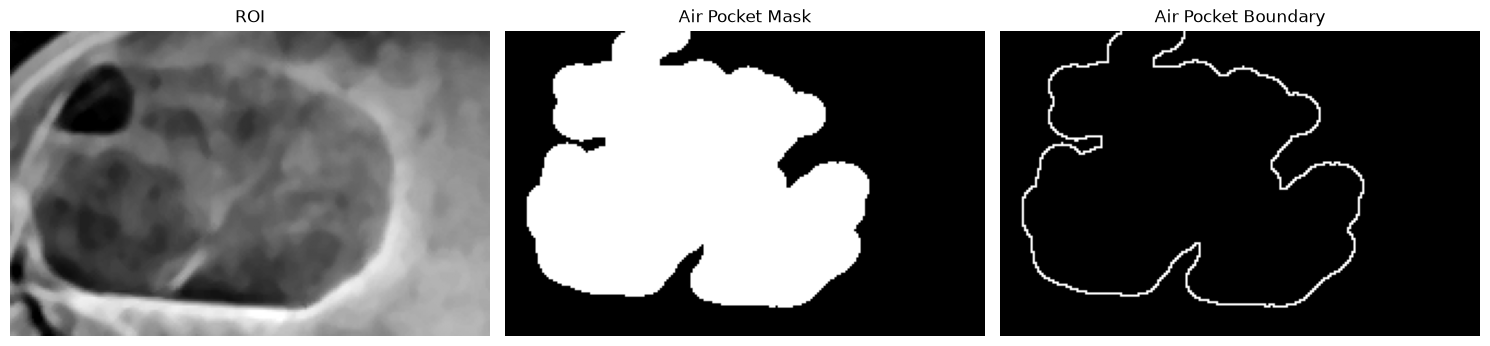

In [14]:
# Step 11 - Boundary Extraction
boundary = cv2.subtract(filled, cv2.erode(filled, np.ones((3, 3), np.uint8)))

show_images([roi, filled, boundary], ["ROI", "Air Pocket Mask", "Air Pocket Boundary"])

### Result: 
### Enhanced image (Steps 1–5): a sharper, higher-contrast version of the X-ray with even brightness, so the air pocket and fracture area are easier to see.
### Air pocket mask (Steps 6–10): a black-and-white image where the trapped air pocket is white and everything else is black.
### Air pocket boundary (Step 11): a thin outline that marks the edge of the pneumocephalus.

# Task 4 Evaluation and Comparision:

## What we test
We change two parameters from the segmentation part. Everything else stays the same.

1. **Threshold value T** in level slicing (Step 7). Tried: 100, 120, 140.
2. **Structuring element size** in opening (Step 8). Tried: 11x11, 21x21, 31x31.

We compare the final mask and count the pocket area in pixels.

In [15]:
# Task 4 - Helper: runs Steps 7 to 10 with chosen parameters, returns final mask
def segment(roi, T, se_size):
    sliced = np.where(roi <= T, 255, 0).astype(np.uint8)
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (se_size, se_size))
    opened = cv2.morphologyEx(sliced, cv2.MORPH_OPEN, se)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(opened, connectivity=8)
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    pocket = (labels == largest).astype(np.uint8) * 255
    filled = ndimage.binary_fill_holes(pocket > 0).astype(np.uint8) * 255
    return filled

T = 100 -> pocket area = 3795 pixels
T = 120 -> pocket area = 14128 pixels
T = 140 -> pocket area = 19089 pixels


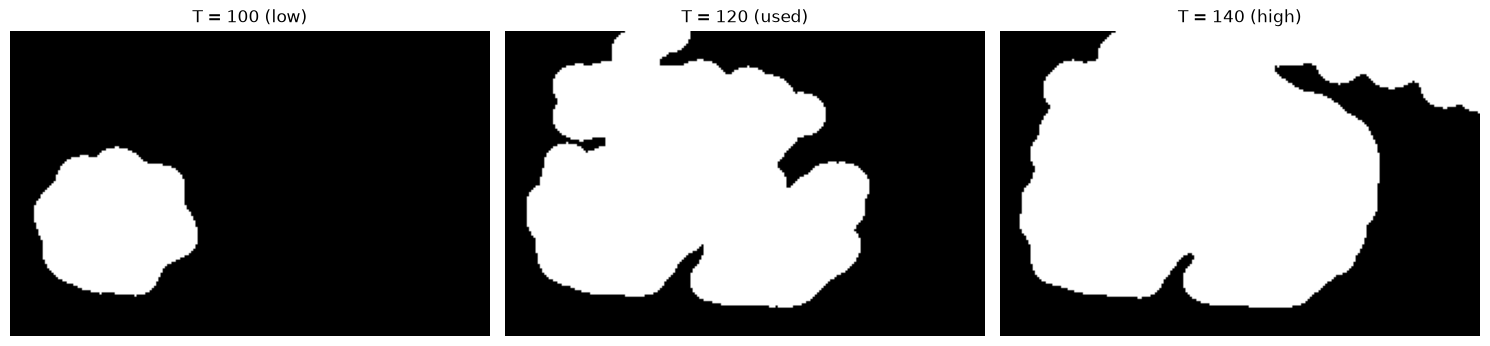

In [16]:
# Experiment 1 - Change threshold T (SE size fixed at 21x21)
masks = []
for T in [100, 120, 140]:
    m = segment(roi, T, 21)
    masks.append(m)
    print(f"T = {T} -> pocket area = {np.sum(m > 0)} pixels")

show_images(masks, ["T = 100 (low)", "T = 120 (used)", "T = 140 (high)"])

### Observations - Experiment 1 (threshold T)
- **T = 100:** too strict. Only the darkest pixels pass. The pocket breaks into pieces and only a small blob is left (about 3800 px). Most of the pocket is missed. This is under-segmentation.
- **T = 120:** the pocket comes out as one connected shape (about 14100 px). It follows the dark region we see in the ROI.
- **T = 140:** too loose. Brain tissue near the pocket also passes. The mask grows past the pocket and touches the top of the ROI (about 19100 px). This is over-segmentation.

**Effect:** T decides how many pixels are called "air". Low T misses the pocket, high T leaks into the brain.

SE = 11x11 -> pocket area = 17423 pixels
SE = 21x21 -> pocket area = 14128 pixels
SE = 31x31 -> pocket area = 9113 pixels


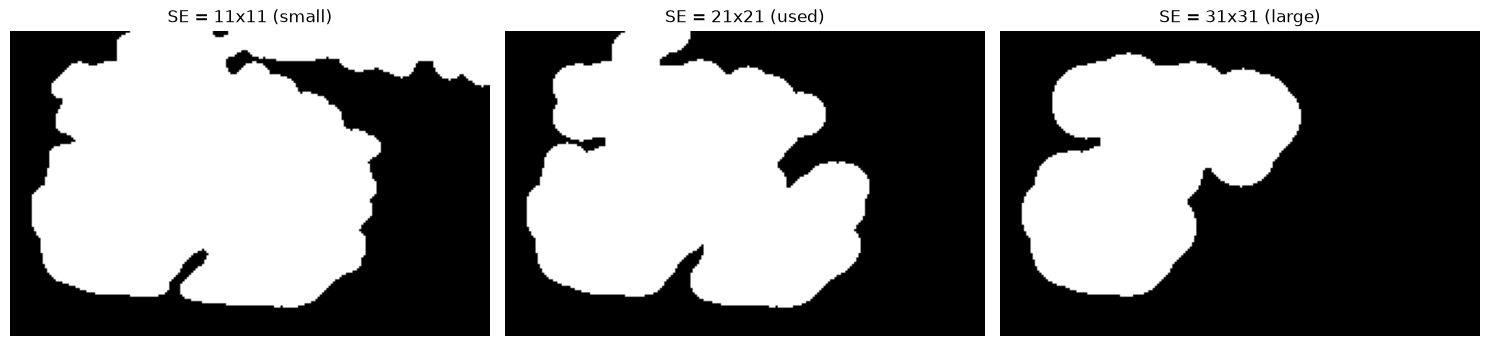

In [17]:
# Experiment 2 - Change opening structuring element size (T fixed at 120)
masks = []
for s in [11, 21, 31]:
    m = segment(roi, 120, s)
    masks.append(m)
    print(f"SE = {s}x{s} -> pocket area = {np.sum(m > 0)} pixels")

show_images(masks, ["SE = 11x11 (small)", "SE = 21x21 (used)", "SE = 31x31 (large)"])

### Observations - Experiment 2 (structuring element size)
- **11x11:** too small. Small specks and thin bridges survive. The edge is jagged and the mask leaks at the top right (about 17400 px).
- **21x21:** specks and bridges are removed. We get one clean, smooth shape (about 14100 px).
- **31x31:** too big. Opening cuts the pocket into separate blobs. "Largest component" then keeps only one part (about 9100 px). Real pocket area is lost.

**Effect:** SE size decides how much detail opening removes. Small keeps noise, large eats the object.

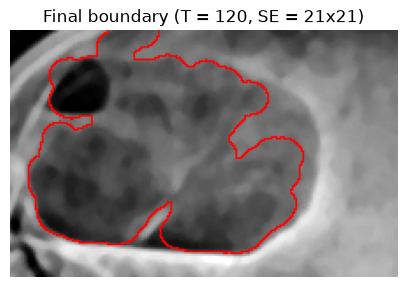

In [18]:
# Final choice - T = 120 and SE = 21x21, boundary drawn on the ROI
best = segment(roi, 120, 21)
boundary = cv2.subtract(best, cv2.erode(best, np.ones((3, 3), np.uint8)))

overlay = cv2.cvtColor(roi, cv2.COLOR_GRAY2RGB)
overlay[boundary > 0] = (255, 0, 0)

plt.figure(figsize=(5, 5))
plt.imshow(overlay)
plt.title("Final boundary (T = 120, SE = 21x21)")
plt.axis("off")
plt.show()

### Most suitable approach
**T = 120 with a 21x21 elliptical structuring element.**

Why:
- It gives one connected region that matches the dark pocket in the ROI.
- No leakage into brain tissue (unlike T = 140 and SE = 11x11).
- No lost parts of the pocket (unlike T = 100 and SE = 31x31).
- Its area (about 14100 px) sits between the under- and over-segmented cases, which is what we expect for the real pocket.
- The red outline sits on the visible edge of the pocket.

# Task 5 Critical Analysis and Conclusion:

### Was the solution successful?
Yes, mostly. The pipeline gives a clear mask and a clean outline of the air pocket. The enhanced image also shows the pocket and fracture area better than the original. But the result depends on hand-picked values (ROI box, T = 120, SE = 21x21), so it is not fully automatic.

### Limitation 1 - Manual ROI
The ROI box is fixed by hand (rows 85 to 225, columns 55 to 275). If another X-ray has the pocket in a different place, the crop will miss it.

### Limitation 2 - Fixed threshold
T = 120 is tuned for this one image. A darker or brighter X-ray would need a new T. Task 4 showed that T = 100 or T = 140 already gives a wrong mask.

Also, there is no ground-truth mask from a doctor. We judge the result by eye only, so we cannot give an accuracy score.

### Possible improvements
- Use Otsu or adaptive thresholding so T is picked automatically.
- Find the skull first (largest contour) and search for the pocket inside it, instead of a hand-drawn ROI.
- Get a labelled mask from a radiologist and compute Dice or IoU scores.
- Try region growing or watershed from a seed inside the pocket for a tighter boundary.

### Summary of observations and findings
- Main image problems: low resolution, noise, uneven brightness, low contrast, soft edges.
- Upscale + median + top-hat/black-hat + gamma + CLAHE + Laplacian gave a clearer image.
- Level slicing + opening + largest component + hole filling isolated the pocket.
- T and SE size are the most sensitive parameters. Small changes change the mask a lot.
- Best settings found: T = 120, SE = 21x21.

# Task 6 Individual Explaination:

### Pipeline in simple words
1. **Load** the X-ray as a grayscale image.
2. **Upscale 2x** so thin lines become thicker and easier to see.
3. **Median filter (5x5)** removes grain noise but keeps edges.
4. **Top-hat / Black-hat (61x61)** fix uneven brightness. Top-hat finds small bright details, black-hat finds small dark details. We add the bright ones and subtract the dark ones. The result has even brightness and better local contrast.
5. **Gamma (1.2) + CLAHE** make the image a bit darker and boost contrast in small tiles, so the dark pocket stands out.
6. **Laplacian sharpening** makes blurry edges crisp. This gives the final enhanced image for viewing.
7. **Crop ROI** around the pocket from the corrected image. We use the corrected image, not the sharpened one, because sharpening and CLAHE add texture that confuses thresholding.
8. **Level slicing:** pixels darker than 120 become white (air), the rest become black.
9. **Opening (21x21)** removes small white specks.
10. **Largest component** keeps only the biggest white region, which is the pocket.
11. **Hole filling** fills small gaps inside the pocket.
12. **Boundary** = mask minus its eroded version. This gives a thin outline of the pocket.

### My modification
I changed the **median filter size from 5x5 to 15x15** and ran the same pipeline again.

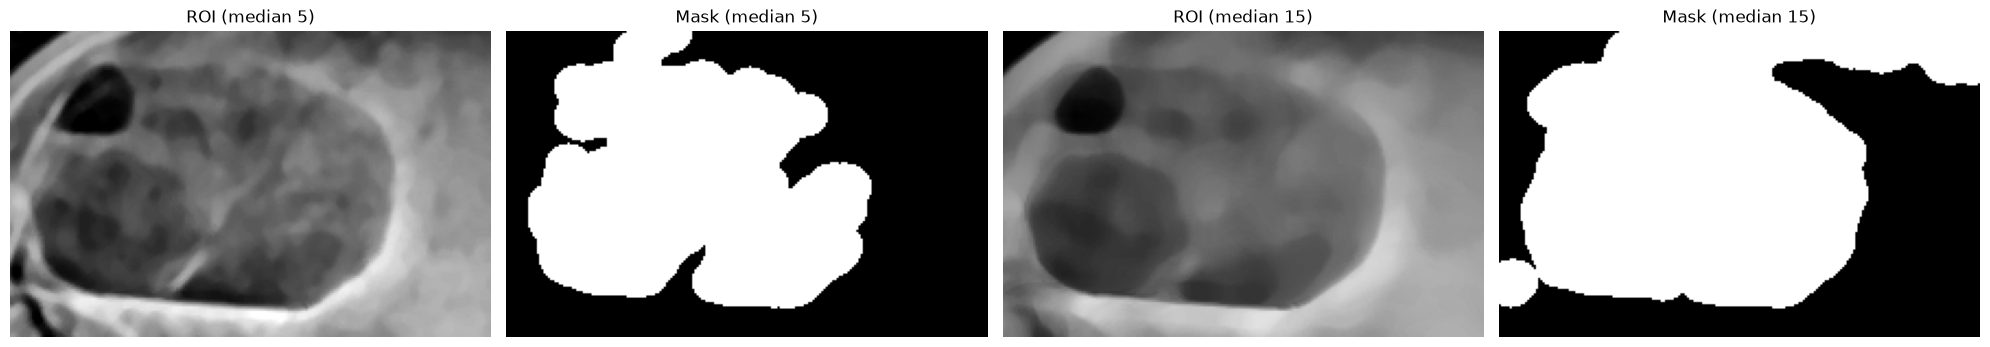

Area with median 5 : 14128 pixels
Area with median 15: 18267 pixels


In [19]:
# Task 6 - Modification: median filter size changed from 5 to 15
denoised_15 = cv2.medianBlur(upscaled, 15)

tophat_15 = cv2.morphologyEx(denoised_15, cv2.MORPH_TOPHAT, k)
blackhat_15 = cv2.morphologyEx(denoised_15, cv2.MORPH_BLACKHAT, k)
corrected_15 = cv2.subtract(cv2.add(denoised_15, tophat_15), blackhat_15)

roi_15 = corrected_15[y1:y2, x1:x2]
mask_5 = segment(roi, 120, 21)
mask_15 = segment(roi_15, 120, 21)

show_images([roi, mask_5, roi_15, mask_15],
            ["ROI (median 5)", "Mask (median 5)", "ROI (median 15)", "Mask (median 15)"])
print("Area with median 5 :", np.sum(mask_5 > 0), "pixels")
print("Area with median 15:", np.sum(mask_15 > 0), "pixels")

### Effect of the change
- With 15x15 the image becomes much smoother. The thin fracture line and small details are blurred away.
- The edge of the pocket also blurs into the brain. More pixels fall under T = 120, so the mask grows (about 18300 px vs 14100 px) and leaks into brain tissue.
- So a bigger median filter removes more noise but also removes real detail. 5x5 is the better balance for this image.